# Project 6 — Retail Performance Analysis Using SQLite, Pandas and Tableau
**Name:** Marcello Velame  
**Objective:** Analyze sales performance and provide evidence-based recommendations.


  **Interactive Dashboards:** [View on Tableau Public] https://public.tableau.com/app/profile/marcello.velame/viz/Project_6_Retail/RevenueAt-RiskAnalysis

## Executive Summary

### Objectives

* Assess the quality of the retail sales data.

* Clean and prepare the datasets for analysis.

* Build a SQLite database and perform SQL joins.

* Engineer new features to support analysis.

* Analyze sales performance through SQL, Pandas, and visualizations.

* Answer key business questions and provide recommendations.

### Key Findings

* Total revenue during this period was 111,656.93. Caveat: This is an estimate, since 132 orders (about 15%) have unknown revenue; see Data Quality Issues for breakdown. 

* The average order value (AOV) is $145.39, based on the 768 orders with known revenue. The 132 orders with unknown revenue are excluded.

* Revenue shows a lot of volatility without showing a particular trend, product or category, up or down. 

* Best seller region could not be called due to missing regions in 48 records.

* 15 high valued customers are at risk for churning, that is 10% of the customer base, which represent 17% (19,252.34) of total calculated revenue. 

* Revenue is concentrated in the top 10 products, representing ~ 63% of total revenue. See visualizations.

* Data available for this analysis show no correlation between longer customer relationship and high average order value. See heatmap and observations for details 



### Data Quality Issues 

* Orders missing unit_price - 118, missing quantity - 16, missing both - 2. Total unknown revenue - 132 orders

* 48 orders missing region → $6,100 unattributed, shown as "Unknown" rather than excluded.

* 79 orders missing category → $12,387 unattributed — large enough on its own to overturn the category ranking, so no top category could be named with confidence.

* 8 phantom customer_ids in orders with no matching customer record → excluded from tenure/churn analysis (149 of 157 customers used)



### Recommendations

* Create strategy to strengthen the relationship with at potential risk of churning customers.

* Establish a more rigorous and standardized data entry practice across stores so future analysis may inform business decisions with a higher degree of certainty.

### Limitations

* Correlation does not establish causation.

* There was no sufficient information within the data to extract any type of profit margins.

* Results are limited to the available data and time period.

* Additional customer and profitability data would strengthen future analyses.

### Assumptions 

* Missing unit_price values - Left unchanged. The assumption here is that estimating the missing unit price would have introduced more error to the data.

* Missing region - changed to unknown and included in the total rather than dropped. The assumption here is that inclusion in the totals is more honest than silent exclusion.

* Missing quantity: left unchanged (NaN). Quantity is specific to each order, so there was no reliable way to estimate it.

* 8 phantom customers - excluded from the analysis of customers at potential risk of churning. There was no search to determine a cause for these, rather they were typos, erroneously deleted customer records, or something else. It was assumed that exclusion and disclosure was sufficient without trying to find the cause.

* Duplicates - After examination, assumed to be full legitimate duplicates and dropped.

* Customer value tier - Assumption: this is a reasonable way to tier customers, with four equal size quartiles, but it is not the only way. A business may have a different method to define high-value. 

* 90-day cut off for "at potential risk of churning" - this threshold was arbitrarily chosen, not derived - nothing in the data indicates that 90 days is the correct way to measure churning for this business. A reasonable sounding number was pick, not a validated one. 


#### Importing Necessary Libraries 

In [302]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import sqlite3

#### Helper Functions

In [303]:
# Function to strip spaces and set title to columns
def clean_text(df, columns):
    for col in columns:
        df[col] = df[col].str.strip().str.title()
    return df

In [304]:
# Function to do a line chart
def line_chart(x, color, ylabel, title, rotation=0, rolling_window=None):
    """
    Plots a line chart of revenue over time.
    x: a Series with the time period as the index and revenue as the values
    rolling_window: optional int (e.g., 3, 6, 12) — if provided, overlays a rolling average line
    """
    plt.figure(figsize=(12, 6))
    plt.plot(x.index.astype(str), x.values, color=color, marker='o', label='Monthly revenue')

    if rolling_window:
        rolling_avg = x.rolling(window=rolling_window).mean()
        plt.plot(rolling_avg.index.astype(str), rolling_avg.values,
                  color='orange', linewidth=2, label=f'{rolling_window}-month rolling avg')
        plt.legend()

    plt.xlabel('Month')
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xticks(rotation=rotation)
    plt.tight_layout()
    plt.show()

In [305]:
# Flexible function to create a bar chart
def bar_chart(x, xlabel, ylabel, title, color='steelblue', rotation=0):
    """
    Plots a bar chart with value labels on top of each bar.
    x: a Series with the category as the index and revenue (or another number) as the values
       (e.g., revenue_region = df.groupby('region')['revenue'].sum())
    xlabel: label for the x-axis (e.g., 'Region')
    title: chart title (e.g., 'Revenue by Region')
    """
    plt.figure(figsize=(17, 8))
    plt.bar(x.index, x.values, color=color, edgecolor='black')

    for index, value in enumerate(x.values):
        if value == 0:
            plt.text(index, 50, 'N/A', ha='center', va='bottom', fontsize=12, color='red', rotation=0)
        else:
            plt.text(index, value, f'{value:,.0f}', ha='center', va='bottom', fontsize=11)

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=rotation)
    plt.tight_layout()
    plt.show()
    

In [306]:
# Function to create a heat map
def heat_map(data, title):
    plt.figure(figsize=(8, 6))
    corr_matrix = data.corr()
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
    plt.title(title)
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [307]:
# multiline chart show how categories drive revenue over time
def multiline_chart(data, title, ylabel, xlabel='Month', rotation=45, legend_title='Category'):
    plt.figure(figsize=(12, 6))
    for category in data.columns:
        plt.plot(data.index.astype(str), data[category], marker='o', label=category)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=rotation)
    plt.legend(title=legend_title)
    plt.tight_layout()
    plt.show()


#### Loading CSV Files

In [308]:
customers = pd.read_csv('raw_customers.csv')
orders = pd.read_csv('raw_orders.csv')
products = pd.read_csv('raw_products.csv')

## Data Quality Assessment & Cleaning
Inspect shape, info, missing values, duplicates, text consistency, dates, and unusual values.

#### Customers

In [309]:
customers.head()

,customer_id,customer_name,region,signup_date,email
0,C149,Nina Costa,South West,08-07-2024,nina.costa@outlook.com
1,C022,kenji haddad,west,2024-03-24,kenji.haddad@outlook.com
2,C049,Grace Rossi,SW,2025-03-28,grace.rossi@mail.com
3,C040,Nadia Moreau,South East,2024-08-12,nadia.moreau@mail.com
4,C140,MARCO FERREIRA,Midwest,05-07-2025,NaN


In [310]:
customers.shape

(154, 5)

In [311]:
customers.dtypes

customer_id      str
customer_name    str
region           str
signup_date      str
email            str
dtype: object

In [312]:
customers.isnull().sum()

customer_id       0
customer_name     0
region            7
signup_date       0
email            13
dtype: int64

#### Convert signup_date to datetime format

In [313]:
customers['signup_date'] = pd.to_datetime(customers['signup_date'], format='mixed')
customers.dtypes

customer_id                 str
customer_name               str
region                      str
signup_date      datetime64[us]
email                       str
dtype: object

#### clean_text() function to eliminate space and capitalize

In [314]:
# Standardize text and clean up spaces
customers = clean_text(customers, ['customer_name', 'region'])

In [315]:
customers.head()

,customer_id,customer_name,region,signup_date,email
0,C149,Nina Costa,South West,2024-08-07,nina.costa@outlook.com
1,C022,Kenji Haddad,West,2024-03-24,kenji.haddad@outlook.com
2,C049,Grace Rossi,Sw,2025-03-28,grace.rossi@mail.com
3,C040,Nadia Moreau,South East,2024-08-12,nadia.moreau@mail.com
4,C140,Marco Ferreira,Midwest,2025-05-07,NaN


#### Duplicates (customers)

In [316]:
duplicated = customers[customers.duplicated(keep=False)]
duplicated

,customer_id,customer_name,region,signup_date,email
21,C129,Ana Costa,NaN,2023-08-05,ana.costa@outlook.com
49,C131,Ana Ferreira,Mid West,2025-06-01,ana.ferreira@mail.com
50,C019,Ines Duarte,Southwest,2023-03-25,ines.duarte@outlook.com
74,C131,Ana Ferreira,Mid West,2025-06-01,ana.ferreira@mail.com
75,C106,James Adams,West,2023-08-29,james.adams@mail.com
118,C019,Ines Duarte,Southwest,2023-03-25,ines.duarte@outlook.com
121,C129,Ana Costa,NaN,2023-08-05,ana.costa@outlook.com
128,C106,James Adams,West,2023-08-29,james.adams@mail.com


In [317]:
customers = customers.drop_duplicates()

In [318]:
duplicated = customers[customers.duplicated(keep=False)]
duplicated

,customer_id,customer_name,region,signup_date,email


#### Standardizing region

In [319]:
#Checking on region unique values
customers['region'].unique()

<StringArray>
['South West',       'West',         'Sw', 'South East',    'Midwest',
  'Southeast',         'Se',         'Ne',          nan,         'Mw',
          'W',  'Northeast',  'Southwest',   'Mid West', 'North East']
Length: 15, dtype: str

In [320]:
customers['region'] = customers['region'].replace({
    'Sw':'Southwest',
    'South West':'Southwest',
    'South East':'Southeast',
    'Mid West':'Midwest',
    'Se':'Southeast',
    'Ne':'Northeast',
    'Mw':'Midwest',
    'W':'West',
    'North East':'Northeast'
})

In [321]:
customers['region'].unique()

<StringArray>
['Southwest', 'West', 'Southeast', 'Midwest', 'Northeast', nan]
Length: 6, dtype: str

### Customers Observations: 

* There were also 13 unknowns in the email column, 7 in the region column.

* 4 non-unique customer_ids were inspected and dropped for being duplicates with string columns in mixed formats, records: 150 rows. 

* Signup_date datatype - string, changed to datetime with format=mix to accommodate the mixed format at data entry. 

* Clean_text function called to standardize mixed text format.

* The column region was standardized to full name the of region, with capital letter, and no abbreviations.

## Orders

In [322]:
orders.head()

,order_id,customer_id,product_id,order_date,quantity,region
0,O1404,C021,P019,2024-03-11,1.0,Northeast
1,O1863,C130,P015,20-Feb-2024,5.0,southeast
2,O1591,C145,P027,09-May-2024,2.0,Southeast
3,O1243,C145,P003,2023-07-07,2.0,W
4,O1438,C136,P027,2023-09-25,1.0,Midwest


In [323]:
orders['order_id'].value_counts()

order_id
O1503    2
O1812    2
O1288    2
O1780    2
O1005    2
        ..
O1212    1
O1580    1
O1538    1
O1197    1
O1176    1
Name: count, Length: 900, dtype: int64

In [324]:
orders.dtypes

order_id           str
customer_id        str
product_id         str
order_date         str
quantity       float64
region             str
dtype: object

In [325]:
orders.isnull().sum()

order_id        0
customer_id     0
product_id      0
order_date      0
quantity       17
region         49
dtype: int64

### Observation 



#### order_date to date_time format

In [326]:
orders['order_date'] = pd.to_datetime(orders['order_date'], format='mixed')
orders.dtypes

order_id                  str
customer_id               str
product_id                str
order_date     datetime64[us]
quantity              float64
region                    str
dtype: object

#### clean_text() eliminate spaces and capitalize

In [327]:
clean_text(orders, ['region'])

,order_id,customer_id,product_id,order_date,quantity,region
0,O1404,C021,P019,2024-03-11,1.0,Northeast
1,O1863,C130,P015,2024-02-20,5.0,Southeast
2,O1591,C145,P027,2024-05-09,2.0,Southeast
3,O1243,C145,P003,2023-07-07,2.0,W
4,O1438,C136,P027,2023-09-25,1.0,Midwest
...,...,...,...,...,...,...
901,O1580,C024,P029,2024-07-15,5.0,West
902,O1503,C148,P029,2023-11-26,3.0,Southeast
903,O1538,C050,P019,2024-07-01,4.0,Southwest
904,O1197,C098,P017,2024-01-26,4.0,West


#### region standardized

In [328]:
orders['region'].unique()

<StringArray>
[ 'Northeast',  'Southeast',          'W',    'Midwest',   'Mid West',
 'North East',         'Mw',         'Sw',  'Southwest',          nan,
 'South West',         'Ne',       'West', 'South East',         'Se']
Length: 15, dtype: str

In [329]:
orders['region'] = orders['region'].replace({
    'Se':'Southeast',
    'South East':'Southeast',
    'Mid West':'Midwest',
    'Se':'Southeast',
    'Ne':'Northeast',
    'Mw':'Midwest',
    'W':'West',
    'North East':'Northeast',
    'Sw':'Southwest',
    'South West':'Southwest'
})

In [330]:
orders['region'].unique()

<StringArray>
['Northeast', 'Southeast', 'West', 'Midwest', 'Southwest', nan]
Length: 6, dtype: str

#### Duplicates (orders)

In [331]:
duplicates = orders[orders.duplicated(keep=False)]
duplicates

,order_id,customer_id,product_id,order_date,quantity,region
40,O1503,C148,P029,2023-11-26,3.0,Southeast
54,O1812,C155,P004,2024-01-13,2.0,Midwest
163,O1288,C109,P028,2023-02-15,2.0,Northeast
225,O1780,C096,P027,2024-12-24,1.0,Southeast
342,O1780,C096,P027,2024-12-24,1.0,Southeast
358,O1005,C059,P005,2024-10-09,NaN,Midwest
436,O1812,C155,P004,2024-01-13,2.0,Midwest
658,O1261,C125,P030,2024-04-08,2.0,NaN
709,O1288,C109,P028,2023-02-15,2.0,Northeast
802,O1261,C125,P030,2024-04-08,2.0,NaN


In [332]:
orders = orders.drop_duplicates()

In [333]:
duplicates = orders[orders.duplicated(keep=False)]
duplicates

,order_id,customer_id,product_id,order_date,quantity,region



### Orders Observations:

* 16 orders have missing quantity (17 before duplicates were removed). Values left as NaN at this stage rather than imputed, since quantity is order-specific and there is no reliable source elsewhere in the data to estimate it. Disposition (whether to exclude these rows from specific downstream calculations) will be revisited once tables are joined and it's clear which analyses they'd affect.

* In addition 48 values (49 before duplicates were removed) in region are unknown, instead of dropping the rows now, the issue will be revisited once tables are joined, just like the missing value for quantity. 

* The column order_date was changed from string to datetime.

* Clean_text function called to eliminate spaces and capitalize names of regions

* String text in region standardized full name of region, no abbreviations.

* 6 duplicate records were inspected and removed.

## Products

In [334]:
products.head()

,product_id,product_name,category,unit_price
0,P005,Laptop Stand,Electronics,17.68
1,P017,STICKY NOTES,office supplies,18.89
2,P019,Whiteboard,Office Supplies,96.75
3,P023,Hiking Backpack,outdoors,115.90
4,P018,Pen Set,Office Supplies,NaN


In [335]:
products.dtypes

product_id      str
product_name    str
category        str
unit_price      str
dtype: object

In [336]:
products.isnull().sum()

product_id      0
product_name    0
category        2
unit_price      3
dtype: int64

#### clean_text() function for product_name and category

In [337]:
products.head()

,product_id,product_name,category,unit_price
0,P005,Laptop Stand,Electronics,17.68
1,P017,STICKY NOTES,office supplies,18.89
2,P019,Whiteboard,Office Supplies,96.75
3,P023,Hiking Backpack,outdoors,115.90
4,P018,Pen Set,Office Supplies,NaN


In [338]:
clean_text(products, ['product_name', 'category'])

,product_id,product_name,category,unit_price
0,P005,Laptop Stand,Electronics,17.68
1,P017,Sticky Notes,Office Supplies,18.89
2,P019,Whiteboard,Office Supplies,96.75
3,P023,Hiking Backpack,Outdoors,115.90
4,P018,Pen Set,Office Supplies,NaN
5,P021,Water Bottle,Outdoors,16.68
6,P016,Desk Organizer,Office Supplies,19.56
7,P026,Headlamp,Outdoors,$102.08
8,P014,Electric Kettle,Home & Kitchen,NaN
9,P031,Travel Pouch,Accessories,32.76


#### Removing currency sign and commas from unit_price and changing it from string to float

In [339]:
products['unit_price'] = products['unit_price'].str.replace('$', '', regex=False).replace('TBD', np.nan)
products['unit_price'] = products['unit_price'].astype(float)

In [340]:
products['unit_price'].unique()

array([ 17.68,  18.89,  96.75, 115.9 ,    nan,  16.68,  19.56, 102.08,
        32.76,  10.9 ,  78.  ,  85.64,  98.2 ,  53.75, 124.73,  81.04,
        92.86,  27.  ,  33.88,  85.18, 112.19,  58.59,  79.47,  22.34,
       109.01,  31.45,  90.22,  12.63])

#### Duplicates (products)

In [341]:
duplicates = products[products.duplicated(keep=False)]
duplicates

,product_id,product_name,category,unit_price
1,P017,Sticky Notes,Office Supplies,18.89
12,P001,Wireless Earbuds,Electronics,85.64
15,P017,Sticky Notes,Office Supplies,18.89
23,P027,Wallet,Accessories,112.19
29,P001,Wireless Earbuds,Electronics,85.64
31,P027,Wallet,Accessories,112.19


In [342]:
products = products.drop_duplicates()

In [343]:
duplicates = products[products.duplicated(keep=False)]
duplicates

,product_id,product_name,category,unit_price


### Products Observations:

* There were 2 unknowns in category and 4 in unit_price.

* product and category were both standardized with a capital letter and spaces.

* unit_price was changed to datatype float and cleaned up so there are no $. Product P012 had a place hold as TBD which was changed to Nan.

* There were 3 duplicate records in the products table. All removed adding up to 31 products.


#### Data Quality Results

In [344]:
data_quality_summary = pd.DataFrame({
    'Field': ['unit_price', 'quantity', 'region', 'category', 'customer_id match'],
    'Missing': ['4 products, 118 orders', '16 orders (2 also missing price)', '48 orders', '79 orders', '8 phantom IDs'],
    'Impact': ['revenue unknown for those orders', 'revenue unknown for those orders', '$6,100 unattributed', '$12,387 unattributed', 'affects per-customer totals']
})
data_quality_summary

,Field,Missing,Impact
0,unit_price,"4 products, 118 orders",revenue unknown for those orders
1,quantity,16 orders (2 also missing price),revenue unknown for those orders
2,region,48 orders,"$6,100 unattributed"
3,category,79 orders,"$12,387 unattributed"
4,customer_id match,8 phantom IDs,affects per-customer totals


## Read tables in SQL - .CSV -> .DB

In [345]:
conn = sqlite3.connect('project6.db')
customers.to_sql('customers', conn, if_exists='replace', index=False)
orders.to_sql('orders', conn, if_exists='replace', index=False)
products.to_sql('products', conn, if_exists='replace', index=False)

31

In [346]:
query = '''
SELECT o.*, c.customer_name, c.region AS customer_region, p.product_name, p.category, p.unit_price
FROM orders o
LEFT JOIN customers c ON o.customer_id = c.customer_id
LEFT JOIN products p ON o.product_id = p.product_id
'''
df = pd.read_sql_query(query, conn)

## Feature Engineering and Visualizations

#### order_date from str -> datetime format

In [347]:
df.head()

,order_id,customer_id,product_id,order_date,quantity,region,customer_name,customer_region,product_name,category,unit_price
0,O1404,C021,P019,2024-03-11 00:00:00,1.0,Northeast,Nadia Duarte,Northeast,Whiteboard,Office Supplies,96.75
1,O1863,C130,P015,2024-02-20 00:00:00,5.0,Southeast,Noah Garcia,Southeast,Notebook Pack,Office Supplies,124.73
2,O1591,C145,P027,2024-05-09 00:00:00,2.0,Southeast,Ana Haddad,Midwest,Wallet,Accessories,112.19
3,O1243,C145,P003,2023-07-07 00:00:00,2.0,West,Ana Haddad,Midwest,Phone Charger,Electronics,NaN
4,O1438,C136,P027,2023-09-25 00:00:00,1.0,Midwest,Nadia Klein,West,Wallet,Accessories,112.19


In [348]:
df['order_date'] = pd.to_datetime(df['order_date'], format='mixed')

In [349]:
df.head()

,order_id,customer_id,product_id,order_date,quantity,region,customer_name,customer_region,product_name,category,unit_price
0,O1404,C021,P019,2024-03-11,1.0,Northeast,Nadia Duarte,Northeast,Whiteboard,Office Supplies,96.75
1,O1863,C130,P015,2024-02-20,5.0,Southeast,Noah Garcia,Southeast,Notebook Pack,Office Supplies,124.73
2,O1591,C145,P027,2024-05-09,2.0,Southeast,Ana Haddad,Midwest,Wallet,Accessories,112.19
3,O1243,C145,P003,2023-07-07,2.0,West,Ana Haddad,Midwest,Phone Charger,Electronics,NaN
4,O1438,C136,P027,2023-09-25,1.0,Midwest,Nadia Klein,West,Wallet,Accessories,112.19


### Observation:

order_date had to be changed into datetime format again because SQL does not support datetime format.

#### Revenue Column

In [350]:
df['revenue'] = (df['quantity'] * df['unit_price'])

#### Order Month Column

In [351]:
df['order_month'] = df['order_date'].dt.to_period('M')

In [352]:
df.head()

,order_id,customer_id,product_id,order_date,quantity,region,customer_name,customer_region,product_name,category,unit_price,revenue,order_month
0,O1404,C021,P019,2024-03-11,1.0,Northeast,Nadia Duarte,Northeast,Whiteboard,Office Supplies,96.75,96.75,2024-03
1,O1863,C130,P015,2024-02-20,5.0,Southeast,Noah Garcia,Southeast,Notebook Pack,Office Supplies,124.73,623.65,2024-02
2,O1591,C145,P027,2024-05-09,2.0,Southeast,Ana Haddad,Midwest,Wallet,Accessories,112.19,224.38,2024-05
3,O1243,C145,P003,2023-07-07,2.0,West,Ana Haddad,Midwest,Phone Charger,Electronics,NaN,NaN,2023-07
4,O1438,C136,P027,2023-09-25,1.0,Midwest,Nadia Klein,West,Wallet,Accessories,112.19,112.19,2023-09


In [353]:
df['revenue'].isnull().sum()

np.int64(132)

### Observation:

* There are 132 unknown revenue values missing, 118 missing unit_price, 16 missing quantity and 2 missing both. Revenue column has been created with the available data and it should be treated as an estimate. 

### Total Period Revenue 

#### 111,656.93


In [354]:
total_revenue = df['revenue'].sum().round(2)
total_revenue 

np.float64(111656.93)

## Revenue Trend over Time Visualization

In [355]:
revenue_by_period = df.groupby(df['order_month'])['revenue'].sum().sort_index()
print(revenue_by_period)

order_month
2023-01    2705.96
2023-02    2047.95
2023-03    3059.98
2023-04    3895.62
2023-05    4491.59
2023-06    2512.64
2023-07    3800.00
2023-08    3254.02
2023-09    3183.75
2023-10    3235.86
2023-11    3076.89
2023-12    3387.58
2024-01    2527.34
2024-02    5151.57
2024-03    4902.52
2024-04    4046.57
2024-05    3773.19
2024-06    5010.44
2024-07    4820.17
2024-08    5219.35
2024-09    4727.57
2024-10    1878.91
2024-11    4620.29
2024-12    3535.03
2025-01    2865.17
2025-02    4713.50
2025-03    3868.56
2025-04    4677.68
2025-05    3444.97
2025-06    3222.26
Freq: M, Name: revenue, dtype: float64


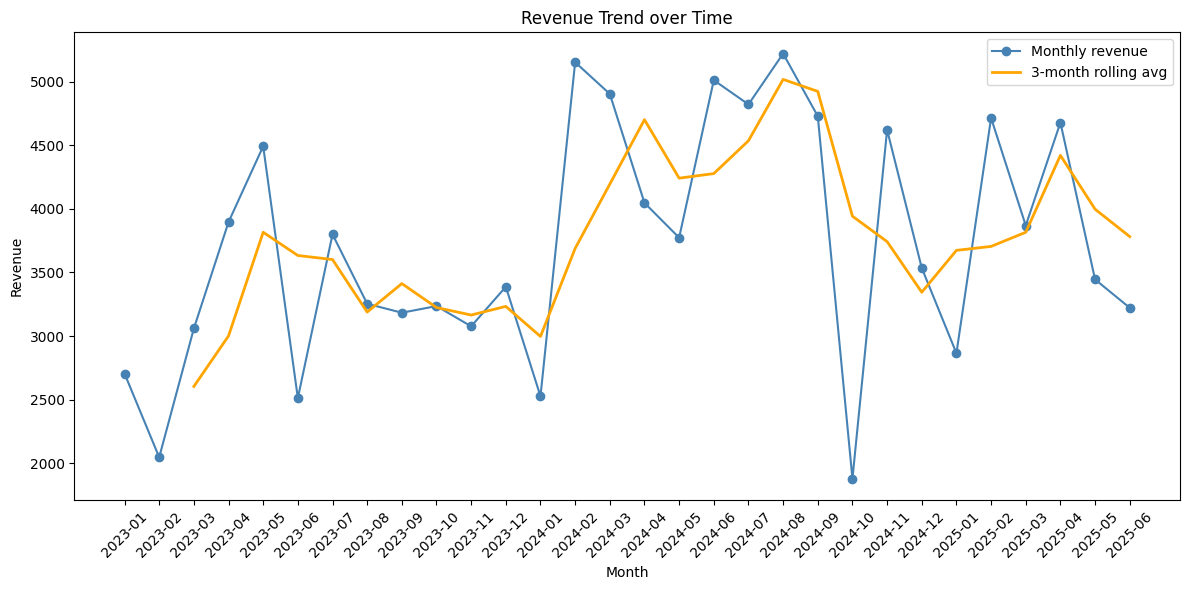

In [356]:

line_chart(revenue_by_period, color='steelblue', ylabel='Revenue',title='Revenue Trend over Time', rotation=45, rolling_window=3)

### Observations:

* As the rolling-average shows, the big picture here shows high month-over-month volatility with no clear trend line ascending or descending. Caveat: There are 132 orders affected by data quality. Revenue calculations should be taken as an estimation, for a breakdown of affected orders, see data quality. 

* The chart does not follow the expected seasonality. December 2024 shows a decline in revenue.

* February 2024 swings upwards to 5,151.57, more than doubling the revenue from January (2,527.34) .    

* It is important to point out the precipitous drop in revenue in October 2024, revenue fell to 1878.91. This may have been an anomaly, however, management may wish to investigate further to look for causes like broader economic pressure, personnel, post back-to-school spending fatigue, price increase, inventory, loss in key customer segment, missing data entry, etc.

* In August 2024 revenue peaks with a total of 5,219.35. At this point, the revenue begins to drop for the month of September and October bring it to the lowest point. Management may wish to investigate further to see if there is a connection between peak and the drop, like inventory depletion, promotion, loss of whole sale and corporate customers, to mention a few. 


#### Investigating Orders

In [357]:
sept_orders = df[df['order_month'].dt.month == 9]
sept_count = len(sept_orders)
sept_count

62

In [358]:
df['order_month'].dt.month.value_counts().sort_index()

order_month
1      70
2      89
3     101
4      81
5     110
6      89
7      64
8      60
9      62
10     55
11     65
12     54
Name: count, dtype: int64

In [359]:
sept_orders = df[df['order_month'].dt.month == 9]
sept_orders['unit_price'].isnull().sum()

np.int64(5)

In [360]:
avg_order_value = df.groupby(df['order_month'].dt.month)['revenue'].mean().round(2)
print(avg_order_value)

order_month
1     139.63
2     163.19
3     137.57
4     177.74
5     125.91
6     134.32
7     162.64
8     154.06
9     143.84
10    108.82
11    142.54
12    160.99
Name: revenue, dtype: float64


### Observation:
* Initial review of the chart suggested the drop occurred in September; period-level analysis confirmed the actual drop was in October 2024. 

## Revenue by Product Visualization

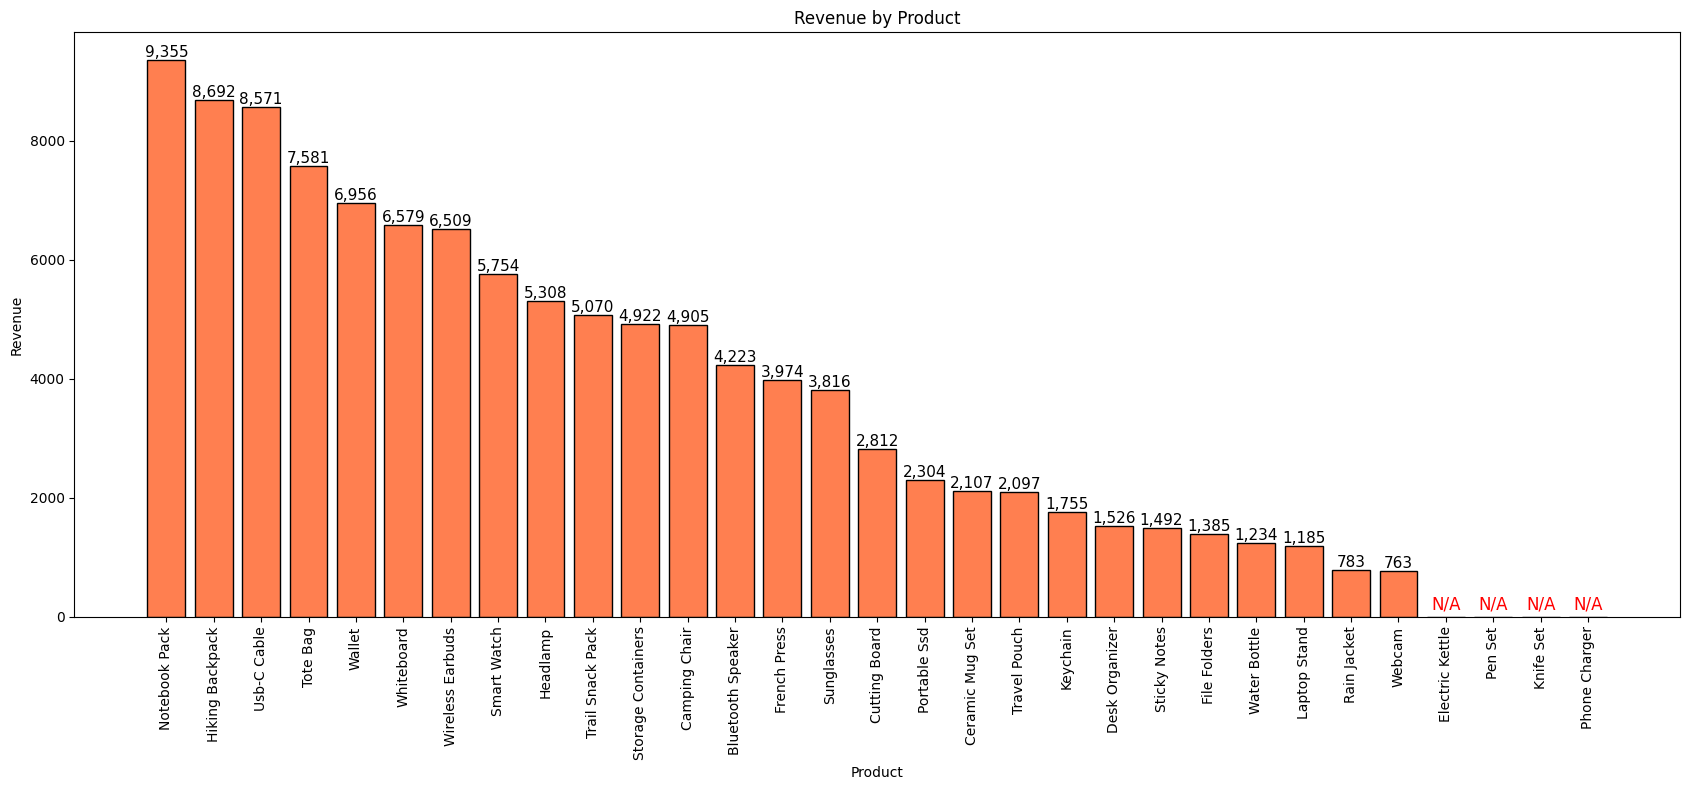

In [361]:
revenue_by_product = df.groupby('product_name')['revenue'].sum().sort_values(ascending=False)
bar_chart(revenue_by_product, xlabel='Product', ylabel='Revenue', title='Revenue by Product', color='coral', rotation=90)


In [362]:
products[products['unit_price'].isnull()][['product_id', 'product_name']]

,product_id,product_name
4,P018,Pen Set
8,P014,Electric Kettle
16,P003,Phone Charger
25,P012,Knife Set


In [363]:
top10 = (revenue_by_product.sort_values(ascending=False).head(10).sum() / revenue_by_product.sum()).round(2)
print(top10)

0.63


### Observations:

* The 4 products indicating N/A on the revenue bar (Electric Kettle, Pen Set, Knife Set and Phone Charger), are the products whose unit_price values are missing. Their sales are unknown, not 0. To show 0 on the chart would be misleading, so N/A was chosen to indicate missing values. Revenue was calculated with available data and should be treated as an estimation.

* The chart shows smooth descending line with Notebook Pack, Hiking Backpack and Usb-C Cable being the highest sellers. The difference between the two highest being ~ 7.4%, and between the first and third places ~ 8.7% difference. So these three products are essentially clustered in first place, there is no one highest seller that stand out.

* The top 10 products account for ~63% of total revenue, showing the majority of sales are concentrated in a relatively small group of top sellers.

## Revenue by Region Visualization

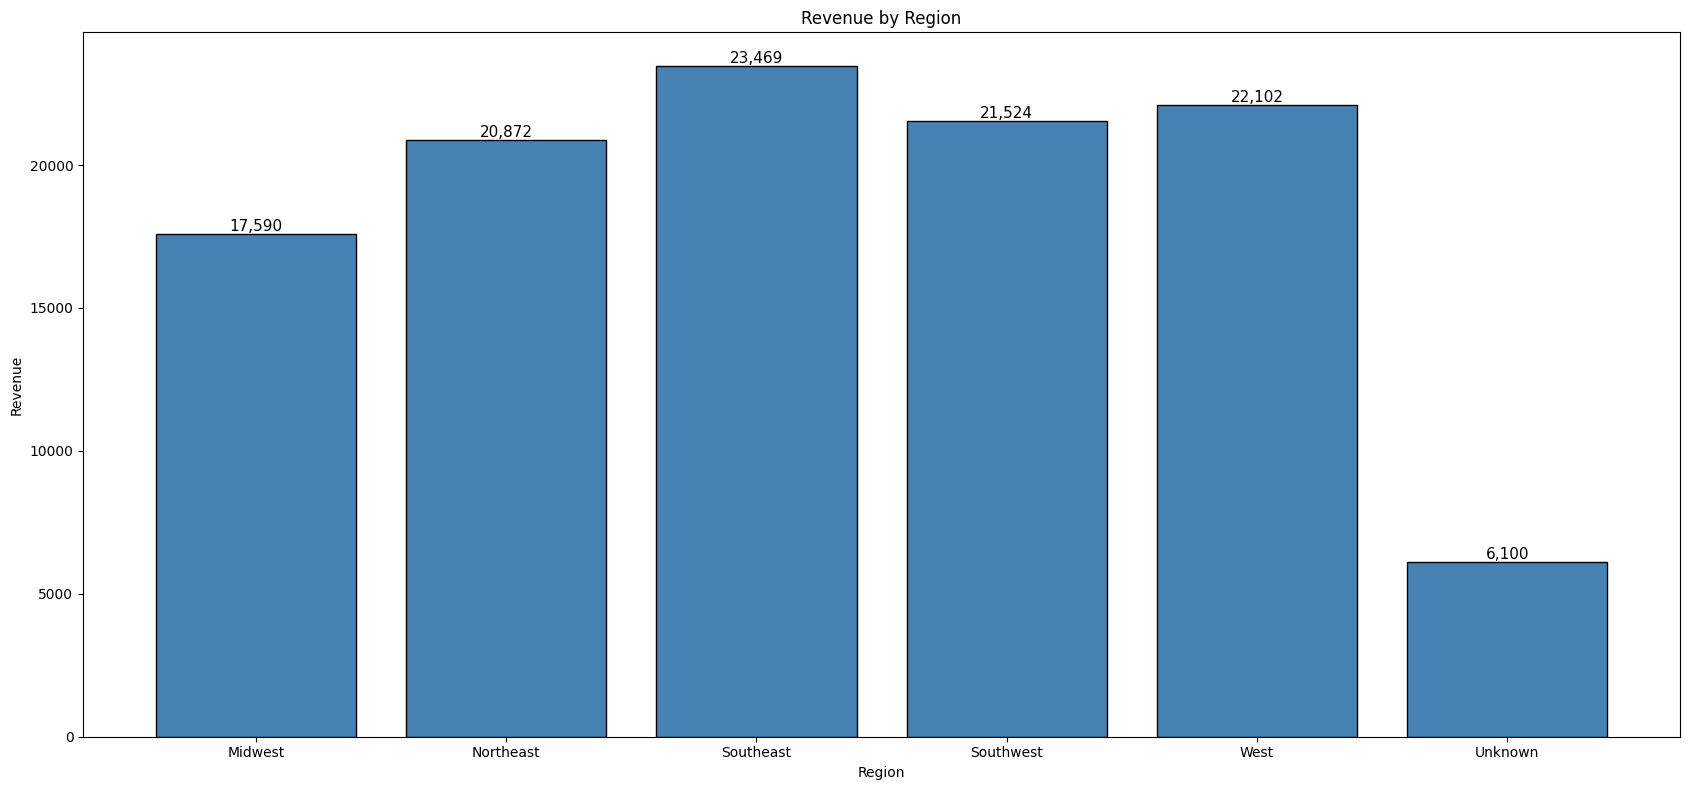

In [364]:
revenue_by_region = df.groupby('region', dropna=False)['revenue'].sum()
revenue_by_region.index = revenue_by_region.index.fillna('Unknown')
bar_chart(revenue_by_region, xlabel='Region', ylabel='Revenue', title='Revenue by Region', color='steelblue', rotation=0)

In [365]:
df[df['region'].isnull()].shape[0]

48

## Checking for Seasonality by Region - Visualization

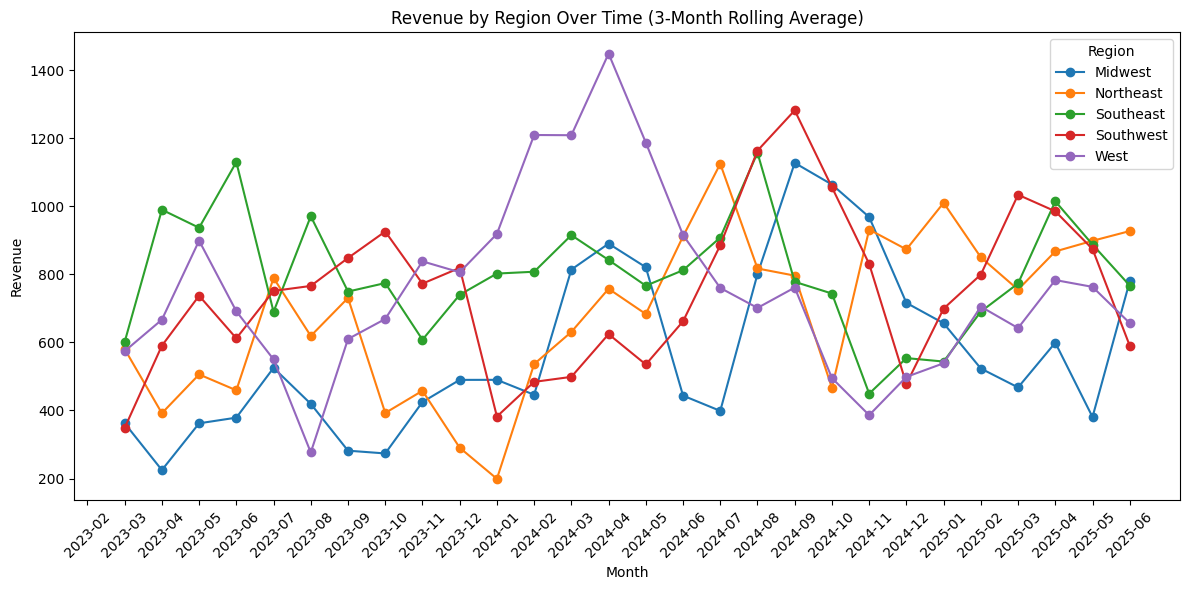

In [366]:
revenue_by_month_region_smooth = df.groupby([df['order_date'].dt.to_period('M'), 'region'])['revenue'].sum().unstack().rolling(window=3).mean()
multiline_chart(revenue_by_month_region_smooth, title='Revenue by Region Over Time (3-Month Rolling Average)', ylabel='Revenue', legend_title='Region')

### Observations

* 48 orders don't have an assigned region to them. These orders are represented as unknown region on the chart above to account for the entire revenue amount, 111,657.00 (difference of ~ $0.07). 

* The best seller region cannot be predicted with any degree of certainty, because of the unknown value is larger than any gap to be measured between the regions (33.4% ~ 5,879) during this period. There is no way of knowing if the unknown value came from one region or all of them. Moreover, the 132 missing must be factored in, which compounds uncertainty. 

* Lastly, the chart shows that the Southeast region has the highest revenue, but the clustering of the regions revenue values must be taken into account here. The regions Southeast, Southwest and West are with ~ 8% of each other. The data does not support calling a top seller region with any degree of certainty. More complete data would yield a clearer answer. 

## Revenue by Category Visualization

In [367]:
revenue_by_category = df.groupby('category', dropna=False)['revenue'].sum()
revenue_by_category.index = revenue_by_category.index.fillna('Unknown')

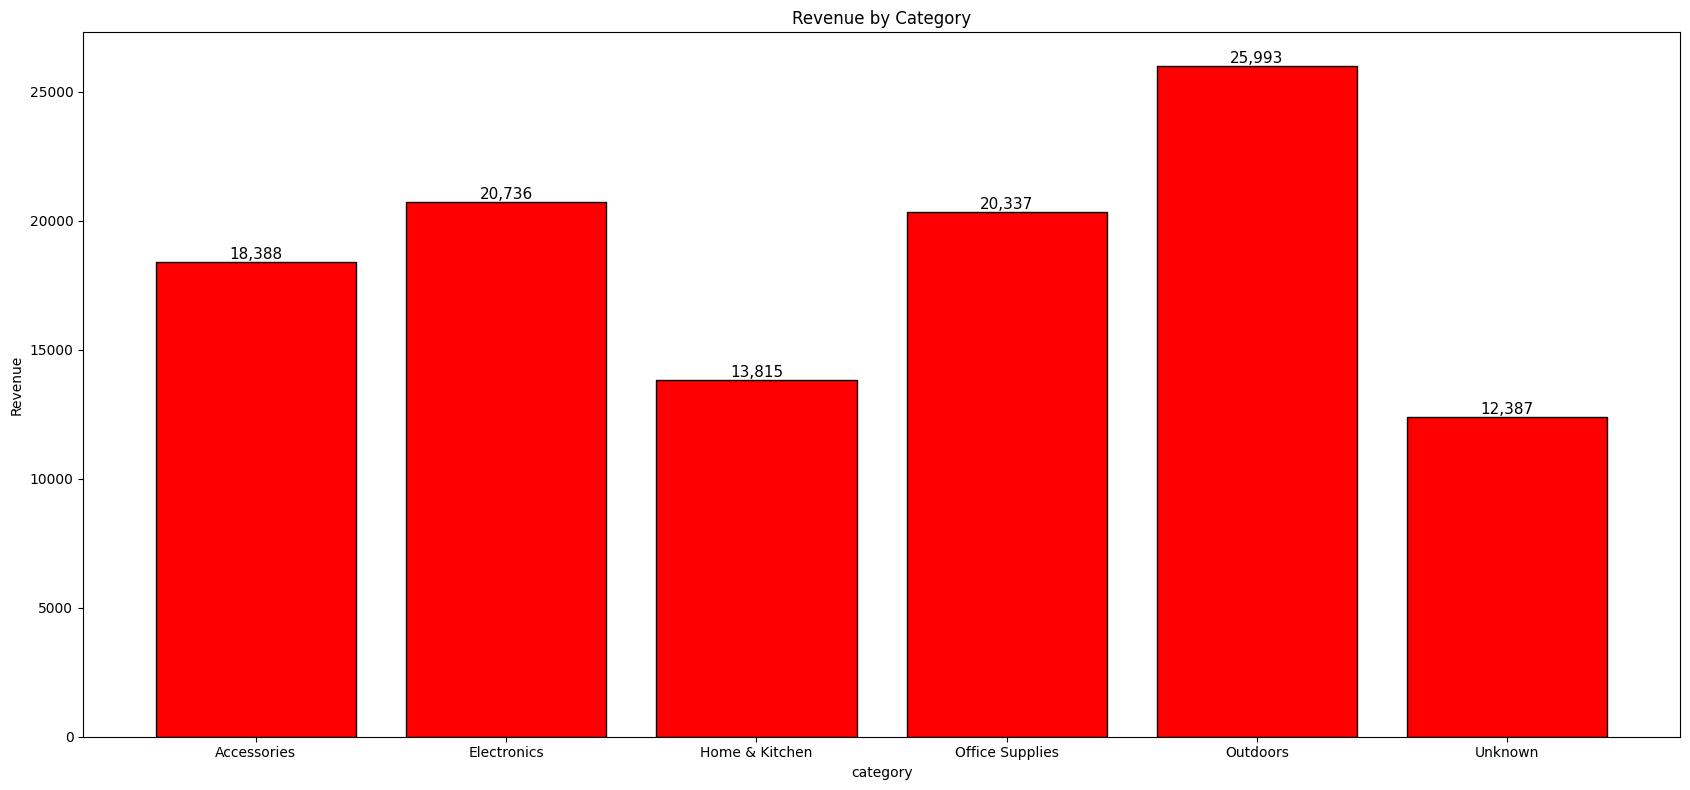

In [368]:
bar_chart(revenue_by_category, xlabel='category', ylabel='Revenue', title='Revenue by Category', color='red')

#### Looking for Missing unit_price values

In [369]:
products[products['unit_price'].isnull()][['product_name', 'category']]

,product_name,category
4,Pen Set,Office Supplies
8,Electric Kettle,Home & Kitchen
16,Phone Charger,Electronics
25,Knife Set,Home & Kitchen


In [370]:
missing_region_ids = df[df['region'].isnull()]['order_id']
missing_category_ids = df[df['category'].isnull()]['order_id']
overlap = set(missing_region_ids) & set(missing_category_ids)
print(len(overlap))

6


In [371]:
df['category'].isnull().sum()

np.int64(79)

### Observations

* 79 orders have no category recorded, separate from the 48 orders missing region — only 6 orders are missing both. This suggests two separate and independent data gaps rather than one shared cause.

* The 4 products with missing unit_price fall into 3 categories, not spread evenly: Home & Kitchen has 2 (Electric Kettle, Knife Set), while Office Supplies and Electronics each have 1. This means Home & Kitchen's revenue may be more understated by missing prices than other categories, independent of the missing-category-field issue above.

* The unknown category (12,387) exceeds the full spread between the highest (Outdoors, 25,993) and lowest (Home & Kitchen, 13,815) known categories — a gap of 12,178. The uncertainty is larger than the entire range being ranked (12,387), so no category can be called the top seller with any degree of confidence.

* Revenue has been calculated with the existing data and should be taken as an estimate.

## Categories Driving Revenue - Visualization

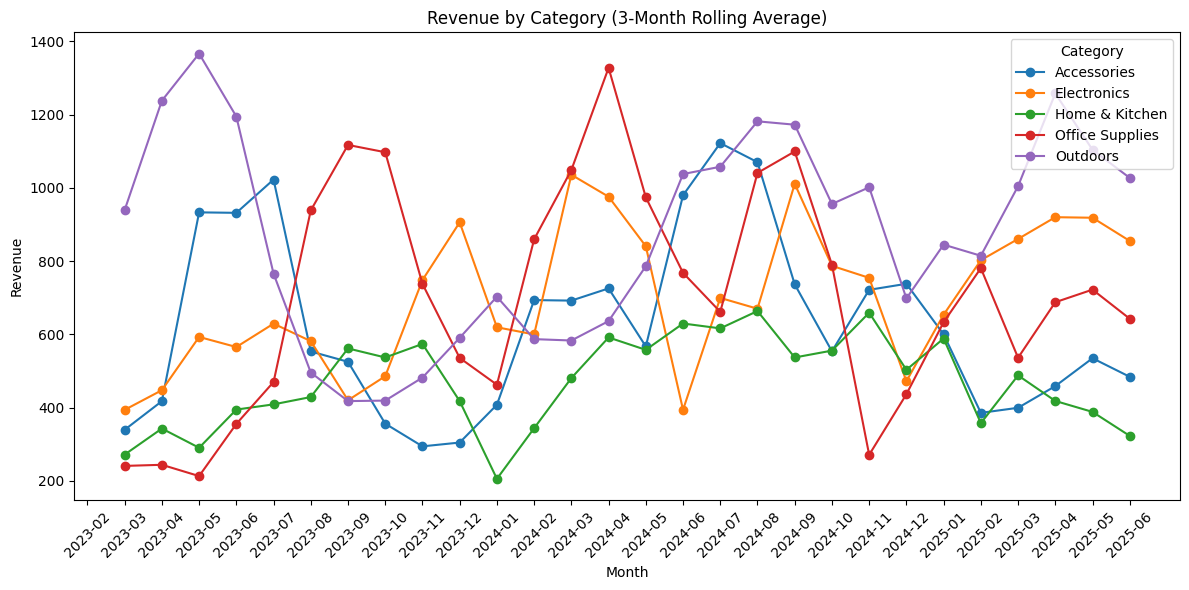

In [372]:
revenue_by_month_category = df.groupby([df['order_date'].dt.to_period('M'), 'category'])['revenue'].sum().unstack()
revenue_by_month_category_smooth = revenue_by_month_category.rolling(window=3).mean()
multiline_chart(revenue_by_month_category_smooth, title='Revenue by Category (3-Month Rolling Average)', ylabel='Revenue', xlabel='Month', rotation=45)

#### Number of Orders in the Outdoor Category

In [373]:
# Checking if outdoors category is order count driven during the spring months (March, April, May)
spring_months = [3, 4, 5]
outdoor_orders = df[(df['category'] == 'Outdoors') & (df['order_date'].dt.month.isin(spring_months))]['order_id'].count()
print(f"Number of orders for Outdoors category in spring months: {outdoor_orders}")

Number of orders for Outdoors category in spring months: 56


#### Average Number of Orders in Category Outdoor by Month

In [374]:
orders_by_month_category = df.groupby([df['order_date'].dt.to_period('M'), 'category'])['order_id'].count().unstack()
orders_by_month_category['Outdoors'].mean()
orders_by_month_category['Outdoors'].describe().round(2)

count    30.00
mean      5.30
std       1.64
min       2.00
25%       4.00
50%       5.00
75%       6.00
max       9.00
Name: Outdoors, dtype: float64

#### Checking revenue during Spring months for Outdoor and West region

In [375]:
west_outdoors = df[(df['region'] == 'West') & (df['category'] == 'Outdoors')].groupby(df['order_date'].dt.to_period('M'))['revenue'].sum()
print(west_outdoors)

order_date
2023-01    306.24
2023-02     78.00
2023-03    425.70
2023-04    545.05
2023-05    231.80
2023-08    102.08
2023-09    109.01
2023-11    234.00
2023-12    403.46
2024-01    491.05
2024-02     50.04
2024-03     25.26
2024-04     37.89
2024-05    645.91
2024-06      0.00
2024-08     83.40
2024-09     25.26
2024-11    115.90
2024-12    231.80
2025-01    511.30
2025-02    524.26
2025-04    546.00
Freq: M, Name: revenue, dtype: float64


In [376]:
west_total = df[df['region'] == 'West'].groupby(df['order_date'].dt.to_period('M'))['revenue'].sum()
(west_outdoors / west_total * 100).round(1)

order_date
2023-01     54.0
2023-02     20.6
2023-03     54.8
2023-04     64.5
2023-05     21.6
2023-06      NaN
2023-07      NaN
2023-08     40.1
2023-09      9.4
2023-10      NaN
2023-11     30.7
2023-12     38.1
2024-01     52.4
2024-02      3.1
2024-03      2.4
2024-04      2.3
2024-05     75.9
2024-06      0.0
2024-07      NaN
2024-08     12.4
2024-09      6.0
2024-10      NaN
2024-11     33.3
2024-12     30.6
2025-01    100.0
2025-02     61.9
2025-03      NaN
2025-04     58.4
2025-05      NaN
2025-06      NaN
Freq: M, Name: revenue, dtype: float64

### Observations:

* A direct check was run to verify whether West's spring revenue spike is actually driven by the Outdoors category. The result is mixed, not confirmed: in 2023, Outdoors accounted for 54.8% (March) and 64.5% (April) of West's revenue — strongly supporting the link. In 2024, however, Outdoors made up only 2.4% and 2.3% of West's revenue in the same two months — the lowest share in the entire 30-month series, directly contradicting the pattern.

* Because the connection holds in one year and breaks down in the next (2025 is inconclusive due to a missing March value), West's spring revenue spike and Outdoors' category-level spring spike should be treated as two separate seasonal patterns rather than one confirmed cause-and-effect story. The earlier claim that West "matches" the Outdoors surge overstated the connection — it holds for one of the two years checked, not both.

## Customer Churning - Visualizations

In [377]:
df[~df['customer_id'].isin(customers['customer_id'])]['customer_id'].nunique()

8

In [378]:
# taking 157 customer_ids and splitting them into 4 categories: High, Mid-High, Mid-Low, Low
customer_revenue = df.groupby('customer_id')['revenue'].sum()
tiers = pd.qcut(customer_revenue, q=4, labels=['Low', 'Mid-Low', 'Mid-High', 'High'])
tier_totals = customer_revenue.groupby(tiers).sum()
high_tier_ids = customer_revenue[tiers == 'High'].index
unmatched_in_high = set(high_tier_ids) & set(df[~df['customer_id'].isin(customers['customer_id'])]['customer_id'])
print(len(unmatched_in_high))

0


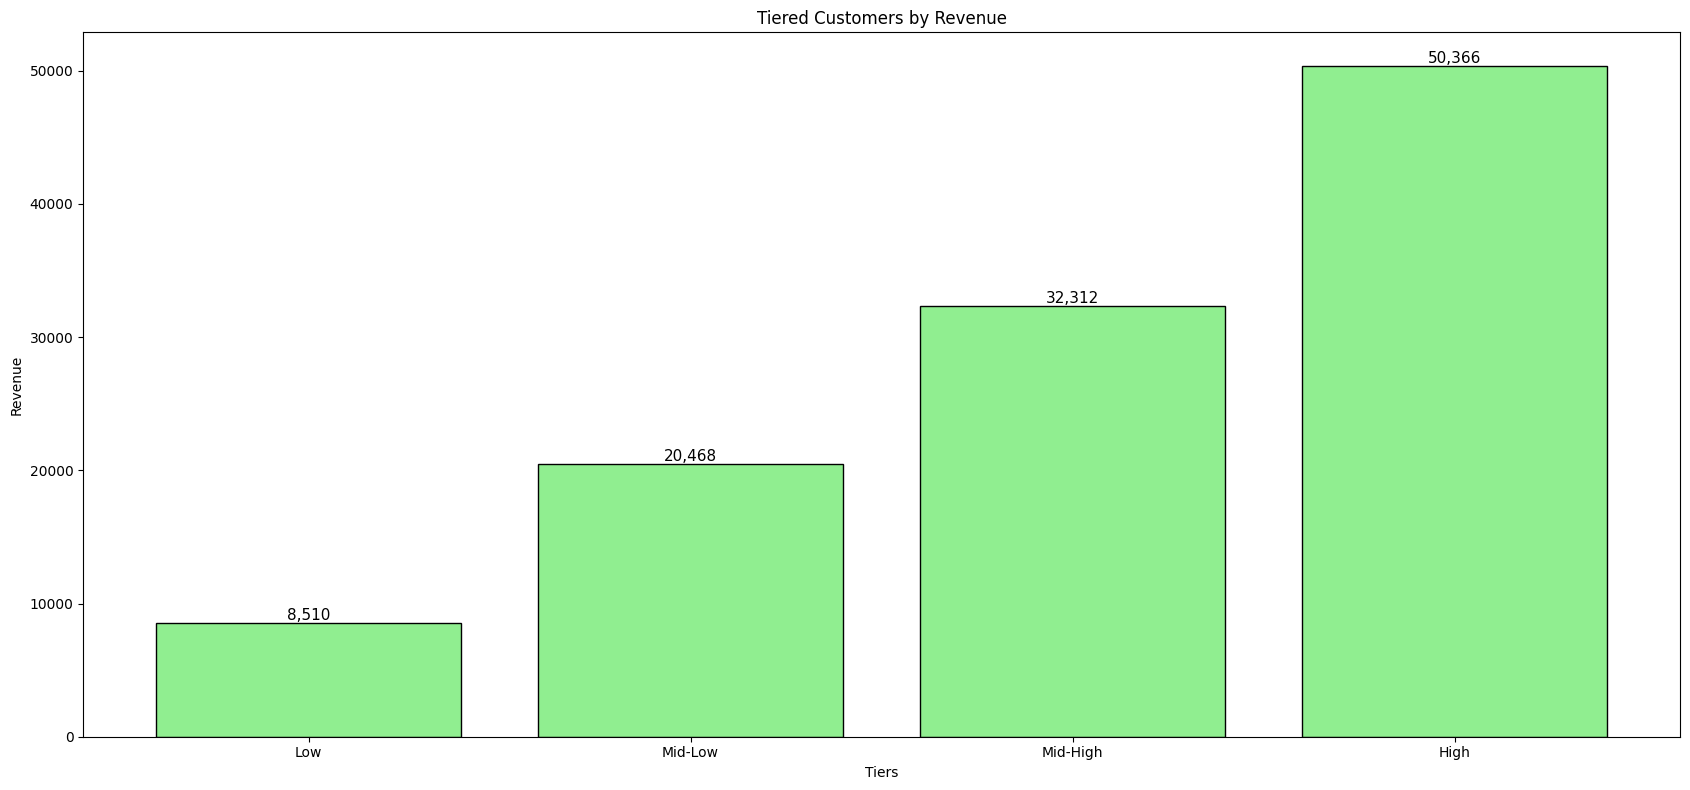

In [379]:
bar_chart(tier_totals, xlabel='Tiers', ylabel='Revenue', title='Tiered Customers by Revenue', color='lightgreen')

In [380]:
reference_date = df['order_date'].max()
last_order = df.groupby('customer_id')['order_date'].max()
days_since_last_order = (reference_date - last_order).dt.days

real_customer_ids = set(customers['customer_id'])
chart_customer_ids = set(days_since_last_order.index)
phantom_in_chart = chart_customer_ids - real_customer_ids
print(len(phantom_in_chart))

8


In [381]:
days_since_last_order_clean = days_since_last_order[days_since_last_order.index.isin(customers['customer_id'])]

In [382]:
bins = [-1, 30, 90, 180, float('inf')]
labels = ['0-30 days', '31-90 days', '91-180 days', '180+ days']
recency_buckets_clean = pd.cut(days_since_last_order_clean, bins=bins, labels=labels)
customers_per_bucket_clean = recency_buckets_clean.value_counts().sort_index()
print(customers_per_bucket_clean)

order_date
0-30 days      28
31-90 days     37
91-180 days    44
180+ days      40
Name: count, dtype: int64


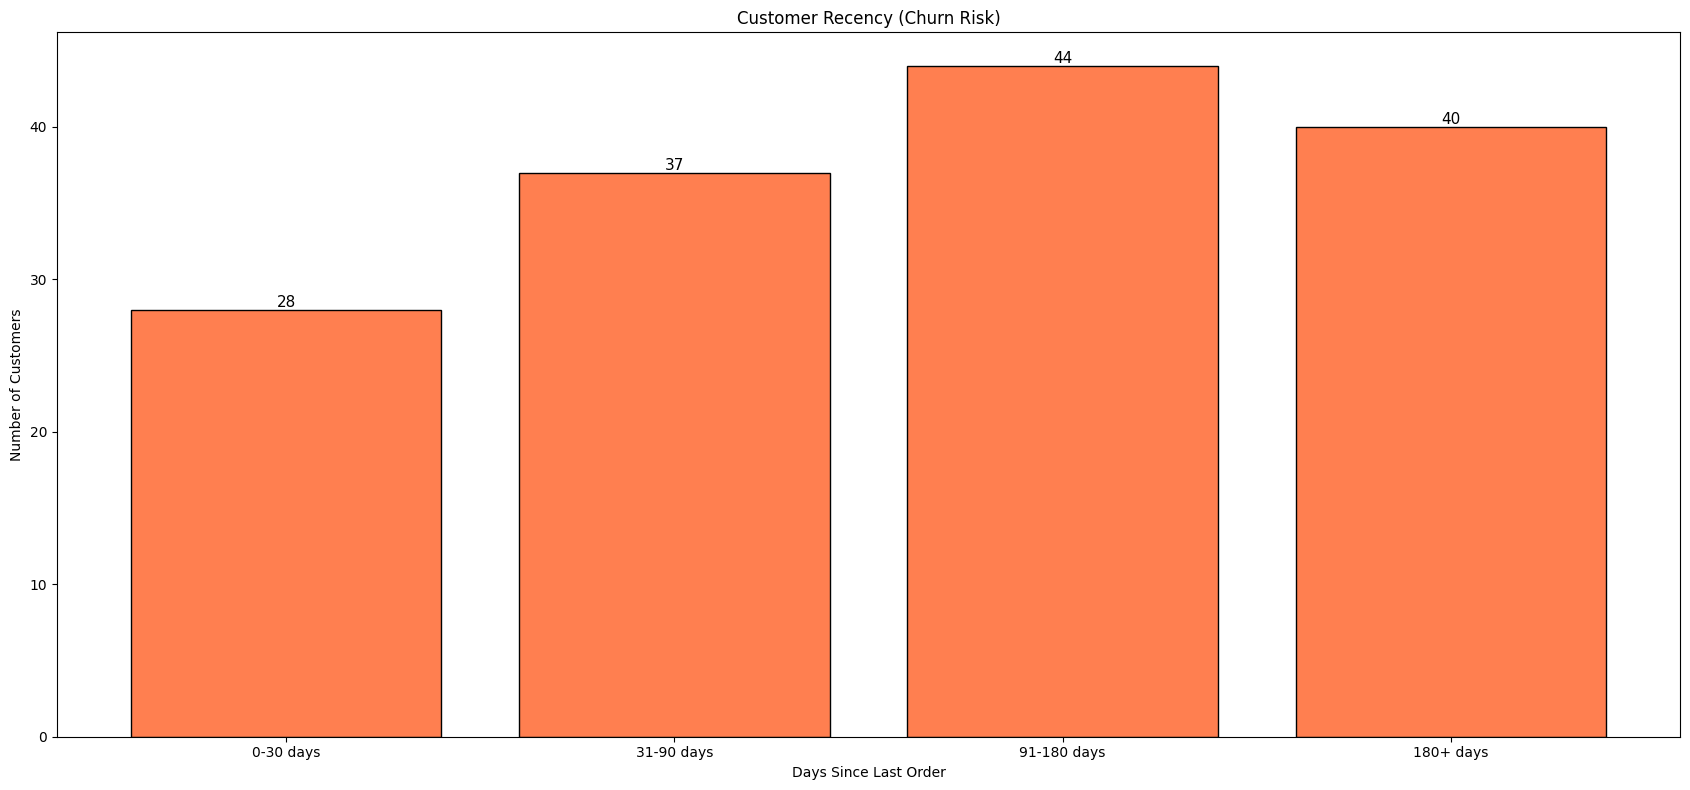

In [383]:
bar_chart(customers_per_bucket_clean, xlabel='Days Since Last Order', ylabel='Number of Customers', title='Customer Recency (Churn Risk)', color='coral')

In [384]:
customers.shape[0]

150

In [385]:
len(chart_customer_ids)

157

In [386]:
at_risk = customers_per_bucket_clean['91-180 days'] + customers_per_bucket_clean['180+ days']
percentage = (at_risk / customers_per_bucket_clean.sum() * 100).round(1)
print(percentage)

56.4


#### High Tier and at Potential Risk Customers Overlap

In [387]:
high_tier_ids = customer_revenue[tiers == 'High'].index
at_risk_ids = days_since_last_order_clean[days_since_last_order_clean > 90].index
overlap = set(high_tier_ids) & set(at_risk_ids)
print(len(overlap))

15


In [388]:
revenue_at_risk = customer_revenue[customer_revenue.index.isin(overlap)].sum().round(2)
print(revenue_at_risk)

19252.34


### High valued customer at risk: 15 (10% of customer base)
### Revenue generated by at risk customers: 19,252.34 (~ 17% of total revenue)

### Observations

* 8 orders with valid revenue point to no existing customer on the customer table. This is relevant information as customer revenue is calculated and tiered, because revenue attributed to no existing customer may be counted, but in this case it will not have a customer attached to it.

* The top 25% of customers generate approximately 45% of total revenue, indicating that a relatively small group of customers contributes disproportionately to overall revenue. 

* The 8 customer_ids with no matching customer record (found earlier) do not fall in the High tier, so this finding isn't affected by that data gap.

* Of 150 real customers, 1 has never placed an order and does not appear in this analysis. Additionally, 8 orders reference customer_ids not present in the customers table; these were excluded from the recency analysis, bringing the total analyzed to 149 real customers.

* Of 149 customers with recorded orders (excluding 8 phantom customer_ids and 1 customer with no orders), 56.4% (84 of 149) have not ordered in over 90 days — a meaningful share of the customer base showing churn risk.

* 15 high valued customers are at risk, representing 10% or the customer base and ~ 17% (19,252.34) of total revenue. Losing this group of customers would have a sizeable impact on the business. This is the strongest and most actionable finding in the customer analysis, and directly answers the question of where retention efforts should be focused first.

## Measuring Relationship between variables

### Building customer_summary table

In [389]:
customer_summary = df.groupby('customer_id').agg(
    total_revenue=('revenue', 'sum'),
    avg_order_value=('revenue', lambda x: x.mean().round(2)),
    order_count=('order_id', 'count')
).reset_index()

In [390]:
customer_summary = customer_summary.merge(customers[['customer_id', 'signup_date']], on='customer_id', how='left')
customer_summary 

,customer_id,total_revenue,avg_order_value,order_count,signup_date
0,C001,943.42,157.24,9,2023-05-22
1,C002,905.88,150.98,6,2024-03-08
2,C003,898.30,128.33,7,2023-04-28
3,C004,933.90,155.65,9,2023-09-27
4,C005,1906.04,211.78,10,2024-07-06
...,...,...,...,...,...
152,C154,269.06,134.53,2,NaT
153,C155,180.44,180.44,1,NaT
154,C157,408.32,408.32,1,NaT
155,C159,549.38,274.69,3,NaT


### Calculating average order value

In [391]:
aov = df['revenue'].mean().round(2)
orders_with_revenue = df['revenue'].notna().sum()
print(f"Average order value: ${aov} (based on {orders_with_revenue} orders with known revenue)")

Average order value: $145.39 (based on 768 orders with known revenue)


#### Finding reference_date

In [392]:
reference_date = df['order_date'].max()

In [393]:
customer_summary['tenure_days'] = (reference_date - customer_summary['signup_date']).dt.days

In [394]:
customer_summary

,customer_id,total_revenue,avg_order_value,order_count,signup_date,tenure_days
0,C001,943.42,157.24,9,2023-05-22,770.0
1,C002,905.88,150.98,6,2024-03-08,479.0
2,C003,898.30,128.33,7,2023-04-28,794.0
3,C004,933.90,155.65,9,2023-09-27,642.0
4,C005,1906.04,211.78,10,2024-07-06,359.0
...,...,...,...,...,...,...
152,C154,269.06,134.53,2,NaT,NaN
153,C155,180.44,180.44,1,NaT,NaN
154,C157,408.32,408.32,1,NaT,NaN
155,C159,549.38,274.69,3,NaT,NaN


#### Checking Phantom Customers

In [395]:
customer_summary['signup_date'].isnull().sum()

np.int64(8)

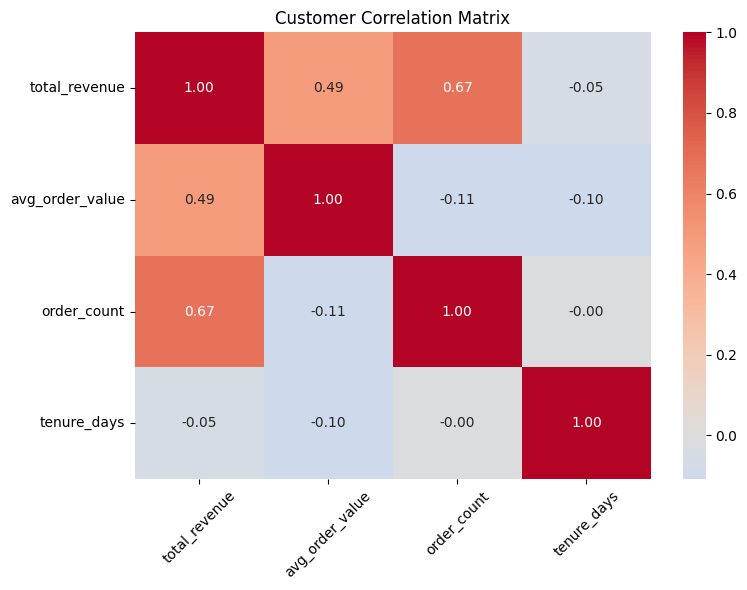

In [396]:
heat_map(customer_summary[['total_revenue', 'avg_order_value', 'order_count', 'tenure_days']], title='Customer Correlation Matrix')
corr_matrix = customer_summary[['total_revenue', 'avg_order_value', 'order_count', 'tenure_days']].corr()

### Observations:

* 8 phantom customer_ids (present in orders but not in the customers table) have no signup_date, resulting in NaN tenure_days. These rows are automatically excluded from any correlation involving tenure, so the tenure-related correlations are based on 149 customers rather than the full 157.
* The heatmap shows no meaningful correlation between customer tenure and average order value(-0.05) at all. How long a customer has been with the company does not predict their spending. Revenue is being driven by order frequency(0.67)  and not by customer tenure or order size. 
* Total revenue and avg_order_value also show a moderate correlation (0.49), though weaker than the order_count relationship (0.67) — order frequency remains the stronger driver of revenue.

## Business Questions

1. Which products or categories generate the most revenue, and how has that changed over time?

There is no one product which generated the most revenue, since the 3 highest sellers (Notebook Pack, Hiking Backpack and Usb-C Cable) are within ~ 8.7% of each other. 
As for categories, a look at the 3-month rolling average revenue by category over time line chart, will show no category remained in the lead long enough to be called the best seller over time. This finding is clearly supported by the revenue by category bar chart, where Outdoors took the lead, however the unknown orders by category represented 12,387.00 of revenue. Enough for even the weakest seller to take over as best seller. 
Outdoors took the lead during the spring months of 2023 and 2024. Spring order volume was only modestly higher than usual (about 6.2 orders per spring month vs. a typical 5.3), so the spike is not clearly explained by order volume alone.
Category was used for the time-series view rather than individual products, since 31 product lines would be unreadable in a line chart.

2. Which customers or customer segments are the most valuable, and which are at risk of churning?

25% of customers (based on 157 customer_IDs with revenue), called High, generated 45% of all revenue, with the Mid-High tier responsible for 29% of all revenue. This suggests customer retention efforts should focus on the Mid-High and High customer base. Of 149 customers 56.4% (84 of 149) have not placed an order in the last 90 days - which is a high percentage of the customer base showing churning risk. 15 high valued customers are at potential risk for churning, representing 10% of the customer base and 17%(19,252.34) of total revenue. Losing this group of customers would have a sizeable impact on the business.

3. Are there regional or seasonal patterns in the data worth highlighting?

It is worth highlighting that the prediction of seasonality made in question 1 is partially confirmed here. Comparing the two multiline charts (category by 
revenue over time and region by revenue over time), both show notable spikes in Spring 2023 — Outdoors at the category level and West at the region level. 
However, no region leads for more than two or three months at a time; West stands out for its spring spikes and a strong finish toward the end of the period, though it does not hold the lead consistently across other months.

A direct check was run to see whether West's spring spike is actually driven by the Outdoors category. The result is mixed: in 2023, Outdoors accounted for   54.8% (March) and 64.5% (April) of West's revenue, strongly supporting a link. In 2024, however, Outdoors made up only 2.4% and 2.3% of West's revenue in 
those same months — the lowest share of the entire period, directly contradicting the pattern. Because the connection holds in one year and breaks down in the next, West's spring spike and Outdoors' spring spike should be treated as two separate seasonal patterns rather than one confirmed cause-and-effect relationship.

4. Where are the data quality gaps(missing ID's, unmatched records, incomplete fields), and how much do they affect the analysis?

Data quality issues were found and documented throughout this project (see consolidated summary above). The issues below are the ones that materially impacted the analysis:

- 132 orders with unknown revenue, missing unit_price - 118, missing quantity - 16, missing both 2.
- 48 orders missing region → $6,100 unattributed, shown as "Unknown" rather than excluded.
- 79 orders missing category → $12,387 unattributed — large enough on its own to overturn the category ranking, so no top category could be named with confidence.
- 8 phantom customer_ids in orders with no matching customer record → excluded from tenure/churn analysis (149 of 157 customers used)

5. What relationships exist between two or more variables that aren't obvious at first glance(e.g. does a longer customer relationship correlate with higher avg order value?)

The data suggests that a longer customer relationship has no correlation (-0.52) with higher avg order value. 
Heatmap also showed that total revenue is positively correlated with the order_count (0.67).

6. If you had to recommend one action to the business based on this data, what would it be, and why?

The data points to the fact that 15 customers, classified as high valued customers, are at potential risk of churning. This represents 10% of total customer base and ~ 17% (19,252.34) of total revenue. This would have a big impact on the business. The most direct action, since these 15 customers are individually identifiable, is targeted outreach to understand why they've gone quiet — the data tells us who is potentially at risk and how much is at stake, but not why. That conversation should inform whether a discount, a payment plan, or something else entirely is the right response for each customer, rather than applying one blanket incentive to the whole group.

In [397]:
customer_summary = customer_summary.set_index('customer_id')
customer_summary['total_revenue'] = customer_summary['total_revenue'].round(2)
customer_summary['tiers'] = tiers
customer_summary['recency_bucket'] = recency_buckets_clean
customer_summary = customer_summary.reset_index()

customer_summary.to_csv('project6_customers.csv', index=False)

In [398]:
df['revenue'] = df['revenue'].round(2)
df.to_csv('project6_orders.csv', index=False)

### Turn correlation matrix into a "long" format and export it:

In [399]:
corr_long = corr_matrix.reset_index().melt(id_vars='index')
corr_long.columns = ['Variable1', 'Variable2', 'Correlation']
corr_long.to_csv('project6_correlation.csv', index=False)